# Figure 4 · Loại hoặc thêm đặc trưng ít thông tin

**Nguồn chính** · Kết quả từng lượt do tác giả công bố. Notebook chạy lại phép phân tích và vẽ hình bằng Python. Lần mở đầu cần Internet để tải và đối chiếu SHA-256.

## Cách đọc thí nghiệm

Figure 4a đánh giá ở hạng 30, dải min–max từ 30 lần xáo. Figure 4b dùng script công bố ở hạng 20, dải phân vị 20%–80% từ 15 lần xáo. Bảng cuối notebook có cả phương án 30 lần xáo và min–max ghi trong chú thích paper. Các biến thể dùng chung dữ liệu tác giả và cách chọn dựa trên validation.

In [1]:
from pathlib import Path
import sys

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "src/analysis.py").is_file())
sys.path.insert(0, str(root))
from IPython.display import Image, display
import matplotlib.pyplot as plt
from src.analysis import analyze
from src.author_data import SOURCES, prepare
from src.plots import export, export_project

source = "ablations"
cache = prepare(source)
print("SHA-256 nguồn:", SOURCES[source].sha256)

SHA-256 nguồn: 25314ccb2d138dae43fd23840f729f62fba0b5f5ab559aeb3727403dedb4e429


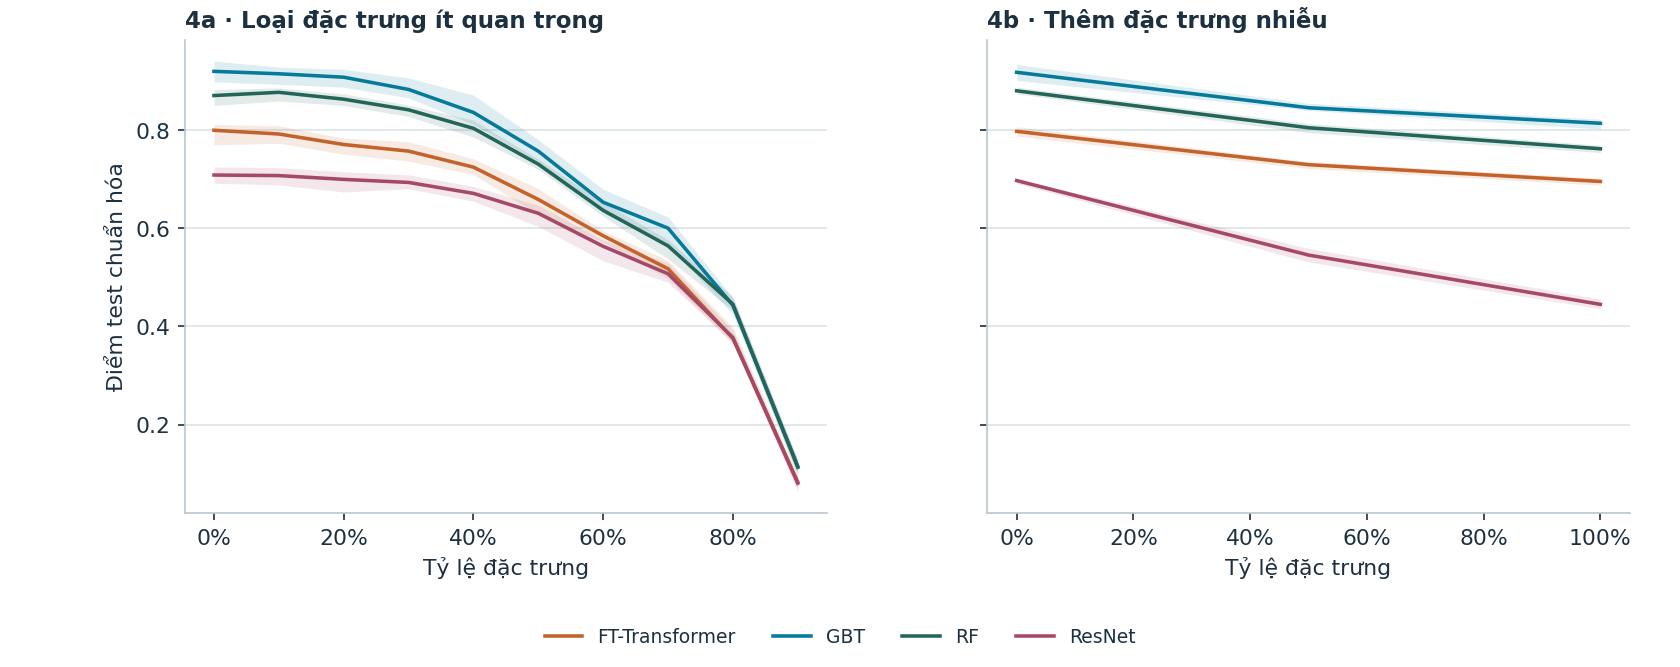

In [2]:
figure_number = 4
scores = analyze(figure_number)
chart = export(figure_number, scores)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}.png")))

## Khác biệt giữa chú thích paper và script Figure 4b

Cùng một dữ liệu đầu vào. Bảng dưới đối chiếu biên dưới và biên trên của hai cách tính.

In [3]:
left, script, caption = scores
comparison = script.merge(caption, on=["model_name", "fraction"], suffixes=("_script", "_caption"))
display(comparison[["model_name", "fraction", "low_script", "high_script", "low_caption", "high_caption"]].round(4))

,model_name,fraction,low_script,high_script,low_caption,high_caption
0,FT Transformer,0.0,0.7879,0.8073,0.7778,0.8190
1,GradientBoostingTree,0.0,0.9016,0.9343,0.8767,0.9458
2,RandomForest,0.0,0.8744,0.8879,0.8622,0.8983
3,Resnet,0.0,0.6916,0.7019,0.6861,0.7120
4,FT Transformer,0.5,0.7221,0.7360,0.7193,0.7516
5,GradientBoostingTree,0.5,0.8407,0.8550,0.8189,0.8649
6,RandomForest,0.5,0.7952,0.8138,0.7821,0.8262
7,Resnet,0.5,0.5314,0.5593,0.5156,0.5728
8,FT Transformer,1.0,0.6880,0.7025,0.6838,0.7197
9,GradientBoostingTree,1.0,0.8027,0.8225,0.7917,0.8338


## Quy trình train trong repo tác giả

**Minh họa quy trình, không có fit mới ở notebook này.** Điểm vào: `src/launch_benchmarks/launch_xps.py · remove_features / add_features`. Tạo hai nhóm đầu vào theo tỷ lệ công bố; loại theo thứ hạng RF hoặc thêm nhiễu Gaussian; train cùng họ mô hình và chấm điểm.

Nếu tái chạy độc lập, dùng cấu hình đầy đủ của đúng model, task và điều kiện từ CSV nguồn. Repo gốc có lệnh chuẩn bị môi trường, launcher và `train_model_on_config`; khóa phiên bản source trước khi chạy. 

### Ví dụ cấu hình đã công bố

Các giá trị dưới đây trích từ dòng đầu tiên của GBT trong từng nhánh, theo thứ tự CSV. File lịch sử dùng tên bộ dữ liệu và loader `real_data`. Launcher pin hiện tại dùng OpenML task ID và `openml_no_transform`, nên cần đối chiếu đầu vào khi chạy lại ví dụ.

In [4]:
import json
import pandas as pd
published = json.loads((root / "evidence/published_config_examples.json").read_text(encoding="utf-8"))
names = ('remove_uninformative_features', 'add_uninformative_features')
display(pd.DataFrame({name: published["examples"][name]["settings"] for name in names}).fillna("—"))

,remove_uninformative_features,add_uninformative_features
data__keyword,credit,MagicTelescope
data__method_name,real_data,real_data
max_test_samples,50000,—
max_train_samples,10000,10000
max_val_samples,50000,—
model__learning_rate,0.01743350178679031,0.00269347249477278
model__loss,exponential,exponential
model__min_samples_leaf,29,3
model__min_samples_split,2,2
model__n_estimators,20,873


## Nguồn

- [Paper NeurIPS 2022](https://papers.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
- [Repo tác giả, commit đã đối chiếu](https://github.com/LeoGrin/tabular-benchmark/tree/9d54cf53d9fd3159e367e70a00005f4fcbf2c79d)
